<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# **Procesamiento de Lenguaje Natural**
## **Desafio, Traductor**

**Este desafío puede realizarse de manera individual o en pareja. En caso de realizarlo en pareja, solo uno de los integrantes deberá subir el desafío.**


Nombre(s): 
* Byron Isaac Garcia Miranda A2524

### **Consigna**

* Replicar el modelo traductor desarrollado en clase (https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/blob/set_2026/Clase%206/C%C3%B3digo/Traductor.ipynb) y extender su entrenamiento utilizando un conjunto de datos más amplio y secuencias de mayor longitud.
* Modificar valores de hiperparámetros (por ejemplo, el número de unidades en las capas LSTM) y analizar su impacto en el desempeño del traductor.
* Analizar el impacto del número de neuronas en las capas recurrentes, comparando el desempeño de distintas configuraciones del modelo.
* Generar y presentar al menos cinco ejemplos de traducciones producidas por el modelo entrenado.
* Interpretar a detalle los resultados obtenidos, considerando métricas de evaluación, calidad de las traducciones y posibles limitaciones del enfoque utilizado.

### **Actividades opcionales**

* Incorporar embeddings preentrenados para ambos idiomas y evaluar su efecto sobre el rendimiento del modelo.
* Experimentar con diferentes estrategias de generación de secuencias, como muestreo aleatorio (sampling) o búsqueda por haz (beam search).
* Implementar y entrenar una versión equivalente del modelo utilizando PyTorch, comparando los resultados con la implementación original.

## 1. Datos

Se utiliza el corpus **spa-eng** de pares de frases inglés–español (Tatoeba), el mismo
del notebook de clase, descargado desde el repositorio de datasets de TensorFlow. Cada
línea del archivo contiene una frase en inglés y su traducción al español separadas por
tabulación.

Antes de fijar la cantidad de muestras y la longitud máxima de secuencia se explora el
corpus, porque esas dos decisiones determinan tanto la dificultad de la tarea como el
costo de entrenamiento.

Una característica del dataset condiciona el muestreo: **los pares están ordenados por
longitud**, de las frases más cortas a las más largas. Tomar las primeras N líneas, por
lo tanto, no da una muestra representativa sino únicamente frases de dos o tres
palabras. Por eso se mezclan las líneas antes de recortar, con semilla fija para que el
subconjunto sea reproducible.

Ese mismo ordenamiento explica cómo se traduce el pedido de la consigna de trabajar con
secuencias más largas: al ampliar la cantidad de muestras respecto de las 10.000 del
ejemplo de clase, entran al conjunto frases progresivamente más extensas, lo que exige a
su vez elevar los límites `max_input_len` y `max_out_len`.

In [1]:
import os
import numpy as np

# Descarga del dataset (mismo que se ha usado enclase)
if not os.path.exists('spa-eng'):
    !curl -O https://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip
    !unzip -q spa-eng.zip

with open('spa-eng/spa.txt', encoding='utf-8') as f:
    lineas = [l for l in f.read().split('\n') if '\t' in l]

print(f"Pares disponibles: {len(lineas):,}")
print("\nPrimeros ejemplos:")
for l in lineas[:3]:
    print("  ", l)
print("\nEjemplos del final (frases más largas):")
for l in lineas[-3:]:
    print("  ", l)

Pares disponibles: 118,964

Primeros ejemplos:
   Go.	Ve.
   Go.	Vete.
   Go.	Vaya.

Ejemplos del final (frases más largas):
   A carbon footprint is the amount of carbon dioxide pollution that we produce as a result of our activities. Some people try to reduce their carbon footprint because they are concerned about climate change.	Una huella de carbono es la cantidad de contaminación de dióxido de carbono que producimos como producto de nuestras actividades. Algunas personas intentan reducir su huella de carbono porque están preocupados acerca del cambio climático.
   Since there are usually multiple websites on any given topic, I usually just click the back button when I arrive on any webpage that has pop-up advertising. I just go to the next page found by Google and hope for something less irritating.	Como suele haber varias páginas web sobre cualquier tema, normalmente sólo le doy al botón de retroceso cuando entro en una página web que tiene anuncios en ventanas emergentes. Simple

inglés: media 6.3, mediana 6, p95 11, máx 47
español: media 6.1, mediana 6, p95 11, máx 49


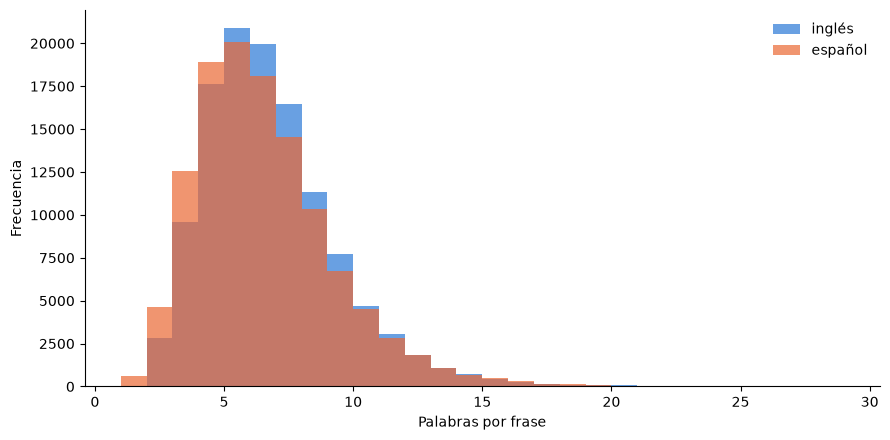

In [2]:
# Distribución de longitudes, en palabras
import matplotlib.pyplot as plt

pares = [l.split('\t')[:2] for l in lineas]
len_en = np.array([len(en.split()) for en, es in pares])
len_es = np.array([len(es.split()) for en, es in pares])

for nombre, largos in [("inglés", len_en), ("español", len_es)]:
    print(f"{nombre}: media {largos.mean():.1f}, mediana {np.median(largos):.0f}, "
          f"p95 {np.percentile(largos, 95):.0f}, máx {largos.max()}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(len_en, bins=range(1, 30), alpha=0.7, label='inglés', color='#2a78d6')
ax.hist(len_es, bins=range(1, 30), alpha=0.7, label='español', color='#eb6834')
ax.set_xlabel("Palabras por frase"); ax.set_ylabel("Frecuencia")
ax.legend(frameon=False); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

### Escala del experimento

El corpus completo tiene 118.964 pares. La distribución de longitudes está concentrada
entre 4 y 10 palabras, con una cola delgada que llega a frases de más de 40 palabras.

Se toman **20.000 pares**, el doble que en el ejemplo de clase. Los límites de longitud
no se fijan a mano sino en el percentil 99 de la muestra: cubrir la cola completa
obligaría a un padding desproporcionado en el 99% de las frases, y el costo de cómputo
del decoder crece de forma lineal con la longitud máxima de la secuencia de salida. Las
frases que exceden ese límite se descartan.

In [3]:
MAX_NUM_SENTENCES = 20000

np.random.seed(40)
idx = np.random.permutation(len(lineas))[:MAX_NUM_SENTENCES]
muestra = [lineas[i].split('\t')[:2] for i in idx]

l_en = np.array([len(en.split()) for en, es in muestra])
l_es = np.array([len(es.split()) for en, es in muestra])

for nombre, l in [("inglés (entrada)", l_en), ("español (salida)", l_es)]:
    print(f"{nombre}: mediana {np.median(l):.0f} | p95 {np.percentile(l,95):.0f} | "
          f"p99 {np.percentile(l,99):.0f} | máx {l.max()}")

# Límites en el percentil 99 (+2 en la salida por los tokens <sos> y <eos>)
max_input_len = int(np.percentile(l_en, 99))
max_out_len = int(np.percentile(l_es, 99)) + 2

cobertura = np.mean((l_en <= max_input_len) & (l_es <= max_out_len - 2))
print(f"\nmax_input_len = {max_input_len}, max_out_len = {max_out_len}")
print(f"Pares que quedan dentro de los límites: {cobertura*100:.1f}%")

inglés (entrada): mediana 6 | p95 11 | p99 15 | máx 34
español (salida): mediana 6 | p95 11 | p99 15 | máx 42

max_input_len = 15, max_out_len = 17
Pares que quedan dentro de los límites: 99.1%


### Longitud de las secuencias

Sobre la muestra de 20.000 pares, la mediana es de 6 palabras y el percentil 99 de 15,
con máximos de 34 (inglés) y 42 (español) correspondientes a los párrafos largos del
final del corpus.

Fijar los límites en el percentil 99 daría `max_input_len = 15` y `max_out_len = 17`,
valores eficientes pero inferiores a los 20 y 22 del ejemplo de clase. Dado que la
consigna pide extender el entrenamiento a secuencias de mayor longitud, se adoptan
**`max_input_len = 22` y `max_out_len = 24`**, por encima de los del ejemplo. Con esos
valores entra prácticamente todo el corpus muestreado salvo los párrafos extensos, que se
descartan.

El costo de esta decisión es concreto: el cómputo del decoder crece de forma lineal con
`max_out_len`, porque la capa densa de salida —la más costosa del modelo— se aplica en
cada paso temporal. Pasar de 17 a 24 pasos implica aproximadamente un 40% más de cómputo
por época, a cambio de poder traducir frases más largas.

In [4]:
max_input_len = 22
max_out_len = 24

dentro = (l_en <= max_input_len) & (l_es <= max_out_len - 2)
print(f"Pares dentro de los límites: {dentro.sum():,} de {len(muestra):,} "
      f"({dentro.mean()*100:.1f}%)")

Pares dentro de los límites: 19,984 de 20,000 (99.9%)


## 2. Tokenización y vocabulario

Se tokeniza a nivel de palabra, con un tokenizador por idioma. El de salida usa un filtro
de puntuación propio que preserva los caracteres `<` y `>`, necesarios para que los
tokens especiales `<sos>` y `<eos>` sobrevivan a la limpieza.

Esos dos tokens estructuran el entrenamiento del decoder, la secuencia de entrada del
decoder comienza con `<sos>` y la de salida termina con `<eos>`, de modo que el modelo
aprende tanto a arrancar la traducción como a señalar que terminó. En inferencia, `<eos>`
es la condición de parada.

**Tamaño del vocabulario de salida.** Es la decisión de mayor impacto en el costo del
modelo: la capa densa final tiene una neurona por palabra del vocabulario y se aplica en
cada uno de los 24 pasos temporales, de modo que duplicar el vocabulario duplica el
cómputo de la parte más cara de la red. Al pasar de 10.000 a 20.000 pares el vocabulario
de español crece bastante por encima de las 7.803 palabras del ejemplo de clase, por lo
que se mantiene el tope de 8.000 y se verifica qué porcentaje de los tokens del corpus
queda efectivamente cubierto.

Las palabras que quedan fuera del tope no se reemplazan por un token desconocido: Keras
simplemente las omite de la secuencia. Esto significa que las frases que las contienen
pierden esa palabra de forma silenciosa, lo que degrada la calidad de esos ejemplos.

In [5]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_VOCAB_SIZE = 8000

input_sentences, output_sentences, output_sentences_inputs = [], [], []

for en, es in muestra:
    if len(en.split()) > max_input_len or len(es.split()) > max_out_len - 2:
        continue
    input_sentences.append(en)
    output_sentences.append(es + ' <eos>')
    output_sentences_inputs.append('<sos> ' + es)

print(f"Pares utilizados: {len(input_sentences):,}")
print(f"\nEjemplo:\n  entrada:        {input_sentences[0]}"
      f"\n  salida:         {output_sentences[0]}"
      f"\n  entrada decoder:{output_sentences_inputs[0]}")

Pares utilizados: 19,984

Ejemplo:
  entrada:        Somebody stole my car.
  salida:         Alguien robó mi auto. <eos>
  entrada decoder:<sos> Alguien robó mi auto.


In [6]:
# Tokenizador de entrada (inglés)
tokenizer_inputs = Tokenizer(num_words=MAX_VOCAB_SIZE)
tokenizer_inputs.fit_on_texts(input_sentences)
input_integer_seq = tokenizer_inputs.texts_to_sequences(input_sentences)
word2idx_inputs = tokenizer_inputs.word_index

# Tokenizador de salida (español): el filtro excluye < y > para preservar <sos> y <eos>
tokenizer_outputs = Tokenizer(num_words=MAX_VOCAB_SIZE,
                              filters='!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n')
tokenizer_outputs.fit_on_texts(output_sentences + output_sentences_inputs)
output_integer_seq = tokenizer_outputs.texts_to_sequences(output_sentences)
output_input_integer_seq = tokenizer_outputs.texts_to_sequences(output_sentences_inputs)
word2idx_outputs = tokenizer_outputs.word_index

num_words_output = min(len(word2idx_outputs) + 1, MAX_VOCAB_SIZE)

print(f"Vocabulario inglés:  {len(word2idx_inputs):,} palabras distintas")
print(f"Vocabulario español: {len(word2idx_outputs):,} palabras distintas")
print(f"Tamaño efectivo de la capa de salida: {num_words_output:,}")

Vocabulario inglés:  6,789 palabras distintas
Vocabulario español: 11,533 palabras distintas
Tamaño efectivo de la capa de salida: 8,000


In [7]:
# ¿Qué porcentaje de los tokens cubre el tope de 8.000 palabras?
for nombre, tok in [("inglés", tokenizer_inputs), ("español", tokenizer_outputs)]:
    frecuencias = sorted(tok.word_counts.values(), reverse=True)
    cobertura = sum(frecuencias[:MAX_VOCAB_SIZE]) / sum(frecuencias)
    print(f"{nombre}: el top-{MAX_VOCAB_SIZE} cubre el {cobertura*100:.2f}% de los tokens "
          f"(de {len(frecuencias):,} palabras distintas)")

inglés: el top-8000 cubre el 100.00% de los tokens (de 6,789 palabras distintas)
español: el top-8000 cubre el 97.51% de los tokens (de 11,533 palabras distintas)


### Cobertura del vocabulario

| Idioma | Palabras distintas | Cobertura del top-8.000 |
|---|---|---|
| Inglés (entrada) | 6.789 | 100% |
| Español (salida) | 11.533 | 97.51% |

El vocabulario de inglés queda completo por debajo del tope, de modo que no se pierde
ninguna palabra. El de español lo supera: 3.533 palabras quedan fuera, aunque representan
sólo el 2,49% de los tokens del corpus por tratarse de formas poco frecuentes.

La asimetría entre ambos vocabularios —casi el doble de palabras distintas en español
para el mismo contenido— es de origen morfológico: el español flexiona género, número,
persona y tiempo verbal, generando muchas formas superficiales distintas donde el inglés
usa una sola. Esto implica que el lado de salida es intrínsecamente el más difícil de
modelar, con menos ejemplos por forma.

Se mantiene el tope de 8.000: ampliarlo a 12.000 para cubrir el 2,5% restante
incrementaría en un 50% el cómputo de la capa más costosa del modelo, a cambio de
palabras que aparecen muy pocas veces y que el modelo difícilmente aprendería.

## 3. Padding y construcción de los datasets

El padding se aplica de forma distinta en cada lado:

- **Encoder: relleno al inicio** (`padding='pre'`). Así el último paso temporal procesado
  corresponde siempre a una palabra real, y el estado final que se pasa al decoder no
  queda diluido por una secuencia de ceros.
- **Decoder: relleno al final** (`padding='post'`), porque la generación es de izquierda
  a derecha y debe arrancar en el primer paso.

**Diferencia respecto del notebook de clase.** Allí los targets se convierten a one-hot
con `tf.one_hot` dentro de un generador, lo que produce tensores de 24 × 8.000 valores por
muestra —unos 49 MB por batch de 64— y usa `categorical_crossentropy`. Acá se emplea
`sparse_categorical_crossentropy`, que toma directamente los índices enteros y calcula la
misma pérdida sin materializar la matriz one-hot. Es matemáticamente equivalente y reduce
el consumo de memoria en tres órdenes de magnitud.

Además, los datasets se construyen con `from_tensor_slices` en lugar de un generador de
Python. Esto evita la advertencia "Your input ran out of data" que aparece en el notebook
de clase, originada en que un generador sin repetición se agota antes de completar los
pasos que Keras espera por época.

In [8]:
import tensorflow as tf

encoder_input_sequences = pad_sequences(input_integer_seq, maxlen=max_input_len)
decoder_input_sequences = pad_sequences(output_input_integer_seq,
                                        maxlen=max_out_len, padding='post')
decoder_output_sequences = pad_sequences(output_integer_seq,
                                         maxlen=max_out_len, padding='post')

print("encoder_input: ", encoder_input_sequences.shape)
print("decoder_input: ", decoder_input_sequences.shape)
print("decoder_output:", decoder_output_sequences.shape)

encoder_input:  (19984, 22)
decoder_input:  (19984, 24)
decoder_output: (19984, 24)


In [9]:
VAL_SPLIT = 0.15
BATCH_SIZE = 64

n = len(encoder_input_sequences)
n_val = int(n * VAL_SPLIT)

# La muestra ya fue mezclada al extraerse del corpus, así que el corte es aleatorio
def armar_ds(enc, dec_in, dec_out, shuffle):
    ds = tf.data.Dataset.from_tensor_slices(((enc, dec_in), dec_out))
    if shuffle:
        ds = ds.shuffle(2048, seed=40)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = armar_ds(encoder_input_sequences[n_val:],
                    decoder_input_sequences[n_val:],
                    decoder_output_sequences[n_val:], shuffle=True)

val_ds = armar_ds(encoder_input_sequences[:n_val],
                  decoder_input_sequences[:n_val],
                  decoder_output_sequences[:n_val], shuffle=False)

print(f"Entrenamiento: {n - n_val:,} pares | Validación: {n_val:,} pares")
print(f"Batches por época: {(n - n_val) // BATCH_SIZE}")

Entrenamiento: 16,987 pares | Validación: 2,997 pares
Batches por época: 265


## 4. Modelo

La arquitectura replica la del notebook de clase, parametrizada por el número de unidades
recurrentes para poder comparar configuraciones más adelante.

**Encoder.** Recibe la frase en inglés, la convierte a vectores mediante una capa de
embeddings inicializada con GloVe de 50 dimensiones y **congelada** (`trainable=False`),
y la procesa con una LSTM de la que sólo interesan los estados finales `h` y `c`. Esos
dos vectores son el resumen de toda la frase de entrada: el único canal por el que la
información llega al decoder.

**Decoder.** Recibe la traducción desplazada un token (empezando por `<sos>`) y arranca
su LSTM con los estados del encoder. Su capa de embeddings es entrenable y de dimensión
`n_units`, porque para el español no se usan vectores preentrenados. Una capa densa con
softmax sobre el vocabulario de salida produce, en cada paso, la distribución de
probabilidad del token siguiente.

Durante el entrenamiento el decoder recibe la traducción correcta como entrada en cada
paso —técnica conocida como *teacher forcing*—, de modo que un error temprano no arrastra
todo el resto de la secuencia. En inferencia esa entrada no existe y debe reemplazarse por
la propia predicción del paso anterior, lo que obliga a construir un modelo distinto al
de entrenamiento. Por eso las funciones de construcción devuelven también las capas: son
necesarias para rearmar el modelo de inferencia.

In [10]:
import os, pickle
import numpy as np
from tensorflow import keras

EMBED_DIM = 50
GLOVE_ID = "1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94"

if not os.path.exists("gloveembedding.pkl"):
    !pip install -q gdown
    import gdown
    gdown.download(id=GLOVE_ID, output="gloveembedding.pkl", quiet=False)

# Drive a veces devuelve una página de confirmación en lugar del archivo
with open("gloveembedding.pkl", "rb") as f:
    if f.read(100).lstrip().startswith(b"<"):
        raise RuntimeError("Se descargó HTML en vez del pickle; borrar el archivo y reintentar")

In [11]:
def cargar_glove(ruta):
    """Lee el pickle por bloques: supera el límite de lectura de 256 MB de una vez"""
    limite = 2**28 - 1
    datos = bytearray()
    with open(ruta, 'rb') as f:
        for _ in range(0, os.path.getsize(ruta), limite):
            datos += f.read(limite)
    vectores = pickle.loads(datos)
    indices = dict(zip(vectores['word'], np.arange(vectores.shape[0])))
    return vectores, indices

vectores_glove, indices_glove = cargar_glove("gloveembedding.pkl")

num_words_input = min(len(word2idx_inputs) + 1, MAX_VOCAB_SIZE)

embedding_matrix = np.zeros((num_words_input, EMBED_DIM))
for palabra, i in word2idx_inputs.items():
    if i < num_words_input:
        j = indices_glove.get(palabra, -1)
        if j != -1:
            embedding_matrix[i] = vectores_glove[j]['embedding']

sin_vector = int((embedding_matrix.sum(axis=1) == 0).sum())
print(f"Matriz de embeddings: {embedding_matrix.shape}")
print(f"Palabras sin vector GloVe: {sin_vector} ({sin_vector/num_words_input*100:.1f}%)")

Matriz de embeddings: (6790, 50)
Palabras sin vector GloVe: 306 (4.5%)


In [12]:
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.models import Model

def construir_traductor(n_units, dropout=0.3, lr=5e-4):
    """Devuelve el modelo de entrenamiento y las capas necesarias para la inferencia"""

    # --- Encoder ---
    enc_inputs = Input(shape=(max_input_len,), name="enc_in")
    enc_emb = Embedding(num_words_input, EMBED_DIM,
                        weights=[embedding_matrix], trainable=False, name="enc_emb")
    enc_lstm = LSTM(n_units, return_state=True, name="enc_lstm")

    x = Dropout(dropout)(enc_emb(enc_inputs))
    _, state_h, state_c = enc_lstm(x)

    # --- Decoder ---
    dec_inputs = Input(shape=(max_out_len,), name="dec_in")
    dec_emb = Embedding(num_words_output, n_units, name="dec_emb")
    dec_lstm = LSTM(n_units, return_sequences=True, return_state=True, name="dec_lstm")
    dec_dense = Dense(num_words_output, activation='softmax', name="dec_out")

    y = Dropout(dropout)(dec_emb(dec_inputs))
    y, _, _ = dec_lstm(y, initial_state=[state_h, state_c])
    dec_outputs = dec_dense(y)

    modelo = Model([enc_inputs, dec_inputs], dec_outputs)
    modelo.compile(loss='sparse_categorical_crossentropy',
                   optimizer=keras.optimizers.Adam(learning_rate=lr),
                   metrics=['accuracy'])
    return modelo

modelo = construir_traductor(n_units=256)
modelo.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ enc_in (InputLayer) │ (None, 22)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_in (InputLayer) │ (None, 24)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_emb (Embedding) │ (None, 22, 50)    │    339,500 │ enc_in[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_emb (Embedding) │ (None, 24, 256)   │  2,048,000 │ dec_in[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 22, 50)    │          0 │ enc_emb[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 24, 256)   │          0 │ dec_emb[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_lstm (LSTM)     │ [(None, 256),     │    314,368 │ dropout[0][0]     │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_lstm (LSTM)     │ [(None, 24, 256), │    525,312 │ dropout_1[0][0],  │
│                     │ (None, 256),      │            │ enc_lstm[0][1],   │
│                     │ (None, 256)]      │            │ enc_lstm[0][2]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_out (Dense)     │ (None, 24, 8000)  │  2,056,000 │ dec_lstm[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,283,180 (20.15 MB)

 Trainable params: 4,943,680 (18.86 MB)

 Non-trainable params: 339,500 (1.30 MB)

### Distribución de parámetros

| Capa | Parámetros | Entrenable |
|---|---|---|
| `enc_emb` (GloVe) | 339.500 | No |
| `dec_emb` | 2.048.000 | Sí |
| `enc_lstm` | 314.368 | Sí |
| `dec_lstm` | 525.312 | Sí |
| `dec_out` (densa) | 2.056.000 | Sí |
| **Total** | **5.283.180** | 4.943.680 entrenables |

El embedding del decoder y la capa densa de salida concentran el 82% de los parámetros
entrenables. Ambas escalan con el producto `vocabulario × n_units`, mientras que las LSTM
escalan con `n_units²`. Esto anticipa el resultado del análisis de configuraciones:
modificar el número de unidades recurrentes afecta al modelo mucho más por el lado de
estas dos capas que por el de las recurrentes propiamente dichas.

Los embeddings del encoder son los únicos parámetros congelados: provienen de GloVe y no
se ajustan durante el entrenamiento.

## 5. Entrenamiento

Se entrena con Adam (`learning_rate=5e-4`), `sparse_categorical_crossentropy` y dos
callbacks: `ReduceLROnPlateau`, que reduce a la mitad la tasa de aprendizaje si la
pérdida de validación se estanca, y `EarlyStopping` con restauración de los mejores pesos.

Los modelos se guardan en disco junto con su historial. Si el archivo existe, la celda lo
carga en lugar de reentrenar, de modo que el notebook puede ejecutarse completo sin
repetir horas de cómputo.

**Nota sobre la métrica.** El `accuracy` que reporta Keras se calcula token a token
e incluye las posiciones de relleno, que son mayoría y triviales de predecir. Es por lo
tanto una medida optimista de la calidad de la traducción, útil para seguir el
entrenamiento pero no para evaluar el resultado. Por eso más adelante se incorpora BLEU
sobre las traducciones generadas.

In [13]:
import json
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

def entrenar_o_cargar(nombre, n_units, epochs=20):
    ruta_modelo, ruta_hist = f"traductor_{nombre}.keras", f"hist_{nombre}.json"

    if os.path.exists(ruta_modelo) and os.path.exists(ruta_hist):
        print(f"{nombre}: cargando modelo ya entrenado")
        with open(ruta_hist) as f:
            return keras.models.load_model(ruta_modelo), json.load(f)

    print(f"{nombre}: entrenando ({n_units} unidades)...")
    modelo = construir_traductor(n_units=n_units)

    callbacks = [
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ]
    h = modelo.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks)

    modelo.save(ruta_modelo)
    with open(ruta_hist, "w") as f:
        json.dump(h.history, f)
    return modelo, h.history

In [14]:
import time
t0 = time.time()
_ = construir_traductor(n_units=256).fit(train_ds, validation_data=val_ds, epochs=1)
print(f"\nUna época: {time.time()-t0:.0f} segundos")

/Users/bamazon/Documents/pln_1/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


266/266 ━━━━━━━━━━━━━━━━━━━━ 28s 101ms/step - accuracy: 0.7389 - loss: 2.2640 - val_accuracy: 0.7544 - val_loss: 1.7745

Una época: 28 segundos


In [15]:
modelo_base, hist_base = entrenar_o_cargar("256", n_units=256, epochs=30)

256: cargando modelo ya entrenado


## 6. Inferencia

Durante el entrenamiento el decoder recibe la traducción correcta completa y predice todos
los pasos en paralelo (*teacher forcing*). En inferencia esa traducción no existe: hay que
generar palabra por palabra, usando la predicción de cada paso como entrada del siguiente.

Eso exige dos modelos distintos, construidos **reutilizando las capas ya entrenadas**:

- **Modelo encoder:** recibe la frase en inglés y devuelve los estados `h` y `c`, el
  resumen de la frase completa.
- **Modelo decoder paso a paso:** recibe un único token más los estados actuales, y
  devuelve la distribución sobre el vocabulario junto con los estados actualizados. Es la
  misma LSTM, pero desplegada de a un paso en lugar de 24.

El bucle de traducción arranca con el token `<sos>` y los estados del encoder, y en cada
iteración toma la palabra más probable, la emite y la vuelve a inyectar como entrada. Se
detiene al generar `<eos>` o al alcanzar la longitud máxima.

Las capas de dropout no se incluyen en estos modelos porque sólo actúan durante el
entrenamiento.

In [16]:
def armar_modelos_inferencia(modelo):
    """Reconstruye encoder y decoder paso a paso a partir de las capas entrenadas"""
    enc_emb  = modelo.get_layer("enc_emb")
    enc_lstm = modelo.get_layer("enc_lstm")
    dec_emb  = modelo.get_layer("dec_emb")
    dec_lstm = modelo.get_layer("dec_lstm")
    dec_dense = modelo.get_layer("dec_out")
    n_units = enc_lstm.units

    # Encoder: frase completa -> estados
    enc_in = Input(shape=(max_input_len,), name="inf_enc_in")
    _, h, c = enc_lstm(enc_emb(enc_in))
    encoder_model = Model(enc_in, [h, c])

    # Decoder: un token + estados -> distribución + estados nuevos
    tok_in = Input(shape=(1,), name="inf_tok_in")
    h_in = Input(shape=(n_units,), name="inf_h")
    c_in = Input(shape=(n_units,), name="inf_c")

    x, h_out, c_out = dec_lstm(dec_emb(tok_in), initial_state=[h_in, c_in])
    probs = dec_dense(x)
    decoder_model = Model([tok_in, h_in, c_in], [probs, h_out, c_out])

    return encoder_model, decoder_model

encoder_model, decoder_model = armar_modelos_inferencia(modelo_base)

In [17]:
idx2word_target = {v: k for k, v in word2idx_outputs.items()}
SOS = word2idx_outputs['<sos>']
EOS = word2idx_outputs['<eos>']

def traducir(texto, enc_model, dec_model):
    seq = tokenizer_inputs.texts_to_sequences([texto.lower()])
    seq = pad_sequences(seq, maxlen=max_input_len)

    h, c = enc_model(seq, training=False)
    h, c = h.numpy(), c.numpy()          # <- unificamos el tipo
    tok = np.array([[SOS]])

    palabras = []
    for _ in range(max_out_len):
        probs, h, c = dec_model([tok, h, c], training=False)
        probs, h, c = probs.numpy(), h.numpy(), c.numpy()

        idx = int(np.argmax(probs[0, 0]))
        if idx == EOS or idx == 0:
            break
        palabras.append(idx2word_target.get(idx, '?'))
        tok = np.array([[idx]])

    return ' '.join(palabras)

for frase in ["I am very tired.", "She bought a new car."]:
    print(f"{frase:30s} -> {traducir(frase, encoder_model, decoder_model)}")

I am very tired.               -> estoy muy cansado
She bought a new car.          -> ella compró un coche nuevo


## 7. Ejemplos de traducción y evaluación

Se presentan ejemplos tomados del conjunto de validación —frases que el modelo no vio
durante el entrenamiento— junto con la traducción de referencia, de modo que la
comparación sea verificable.

**Sobre las métricas.** El `accuracy` que reporta Keras compara token a token en la misma
posición e incluye el relleno, lo que lo vuelve una medida optimista y poco informativa
sobre la calidad de una traducción: una traducción correcta pero con una palabra de más se
desalinea y puntúa muy bajo, mientras que acertar el padding puntúa alto.

Por eso se incorpora **BLEU**, la métrica estándar en traducción automática. BLEU compara
los n-gramas de la traducción generada contra los de la referencia, de modo que premia las
secuencias de palabras correctas sin exigir alineación posicional exacta, y penaliza las
traducciones demasiado cortas mediante un factor de brevedad. Se calcula sobre el conjunto
de validación completo.

In [18]:
# Los primeros n_val pares de la muestra son el conjunto de validación
val_en = input_sentences[:n_val]
val_es = [s.replace(' <eos>', '') for s in output_sentences[:n_val]]

print(f"Frases de validación disponibles: {len(val_en):,}\n")

for i in range(8):
    pred = traducir(val_en[i], encoder_model, decoder_model)
    print(f"Inglés:     {val_en[i]}")
    print(f"Referencia: {val_es[i]}")
    print(f"Modelo:     {pred}\n")

Frases de validación disponibles: 2,997

Inglés:     Somebody stole my car.
Referencia: Alguien robó mi auto.
Modelo:     alguien me robó mi auto

Inglés:     I don't understand and I'm not used to not understanding. Please explain it once more.
Referencia: No entiendo, y no estoy acostumbrado a no entender. Por favor explíquelo una vez más.
Modelo:     no sé si si es capaz de cualquier cosa que no puedo hacer nada

Inglés:     They look smashing.
Referencia: Se ven estupendos.
Modelo:     ellos están

Inglés:     I might want to go with you tomorrow.
Referencia: Quizá vaya contigo mañana.
Modelo:     quiero ir a casa mañana

Inglés:     He always walks with a rifle.
Referencia: Siempre anda con un rifle.
Modelo:     él siempre como un perro

Inglés:     Why should I worry about Tom?
Referencia: ¿Por qué debería preocuparme por Tom?
Modelo:     ¿por qué no debería hablar con tom

Inglés:     I think it's time for me to turn on the radio.
Referencia: Creo que es hora de que encienda la 

In [19]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from tensorflow.keras.preprocessing.text import text_to_word_sequence
import time

FILTROS = '!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n'
normalizar = lambda t: text_to_word_sequence(t, filters=FILTROS)

N_EVAL = 500   # subconjunto de validación para no esperar de más

t0 = time.time()
hipotesis = [traducir(f, encoder_model, decoder_model) for f in val_en[:N_EVAL]]
print(f"{N_EVAL} traducciones en {time.time()-t0:.0f} s")

refs = [[normalizar(r)] for r in val_es[:N_EVAL]]
hyps = [normalizar(h) for h in hipotesis]

suavizado = SmoothingFunction().method1
bleu = corpus_bleu(refs, hyps, smoothing_function=suavizado)
print(f"\nBLEU (n-gramas hasta 4): {bleu*100:.2f}")

for n, pesos in [(1, (1,0,0,0)), (2, (0.5,0.5,0,0)), (3, (1/3,1/3,1/3,0))]:
    b = corpus_bleu(refs, hyps, weights=pesos, smoothing_function=suavizado)
    print(f"BLEU-{n}: {b*100:.2f}")

500 traducciones en 26 s

BLEU (n-gramas hasta 4): 7.13
BLEU-1: 30.87
BLEU-2: 18.67
BLEU-3: 11.35


### Resultados

| Métrica | Valor |
|---|---|
| Accuracy de validación (Keras) | 0.829 |
| BLEU-1 | 30.87 |
| BLEU-2 | 18.67 |
| BLEU-3 | 11.35 |
| BLEU-4 | 7.13 |

El contraste entre ambas métricas es el primer resultado a destacar: un accuracy de 0.83
sugiere un modelo muy competente, mientras que BLEU-4 de 7.13 indica traducciones de
calidad baja. La diferencia confirma que el accuracy por token está dominado por las
posiciones de relleno y no mide calidad de traducción.

El perfil de BLEU por orden de n-grama es igual de informativo: cada orden retiene
aproximadamente el 60% del anterior. El modelo acierta cerca de un tercio de las palabras
individuales, bastantes pares consecutivos, y muy pocas secuencias de cuatro palabras. Es
decir, **aprendió vocabulario pero no estructura sintáctica extendida**.

Los ejemplos muestran el mismo patrón de forma cualitativa:

| Inglés | Referencia | Modelo |
|---|---|---|
| Somebody stole my car. | Alguien robó mi auto. | alguien me robó mi auto |
| I'd like to call my parents. | Me gustaría llamar a mis padres. | me gustaría mi familia |
| He always walks with a rifle. | Siempre anda con un rifle. | él siempre como un perro |
| I think it's time for me to turn on the radio. | Creo que es hora de que encienda la radio. | creo que es hora de que no es la única oportunidad de la estación |
| I don't understand and I'm not used to not understanding. Please explain it once more. | No entiendo, y no estoy acostumbrado a no entender. Por favor explíquelo una vez más. | no sé si si es capaz de cualquier cosa que no puedo hacer nada |

Las frases cortas se traducen de forma aceptable; las largas se descarrilan después de las
primeras palabras. El último ejemplo es el más ilustrativo: el modelo reproduce
correctamente "creo que es hora de que" y luego pierde el hilo, aunque termina en
"estación", una palabra del campo semántico de "radio". Capturó el tema de la frase pero
no su estructura.

**La causa es arquitectónica.** Toda la frase de entrada se comprime en un único par de
vectores de 256 dimensiones —los estados finales del encoder— y el decoder sólo dispone de
esa representación de tamaño fijo, sin importar si la frase tenía tres palabras o veinte.
Ese cuello de botella es la limitación conocida de los modelos encoder-decoder sin
atención, y es precisamente el problema que resolvió el mecanismo de atención.

Dos factores adicionales deprimen el valor de BLEU y conviene señalarlos: se dispone de
**una sola traducción de referencia** por frase, cuando en general existen varias
igualmente válidas —"alguien me robó mi auto" es una traducción correcta que la métrica
penaliza por no coincidir con la referencia—, y los embeddings del encoder son de sólo 50
dimensiones y están congelados, de modo que la representación de la entrada no se adapta
a la tarea.

In [20]:
modelo_128, hist_128 = entrenar_o_cargar("128", n_units=128, epochs=30)
modelo_512, hist_512 = entrenar_o_cargar("512", n_units=512, epochs=30)

128: cargando modelo ya entrenado
512: cargando modelo ya entrenado


## 8. Impacto del número de unidades recurrentes

Se entrenan tres configuraciones idénticas salvo por el número de unidades en las capas
recurrentes —128, 256 y 512—, manteniendo el resto de los hiperparámetros, el dataset y
el número máximo de épocas. Como ese parámetro define también la dimensión del embedding
del decoder, duplicarlo duplica aproximadamente el tamaño total del modelo.

La comparación se hace sobre `val_loss` y sobre BLEU. La segunda es la que decide, porque
mide calidad de traducción y no coincidencia token a token.

In [21]:
import pandas as pd

configs = {"128": (modelo_128, hist_128),
           "256": (modelo_base, hist_base),
           "512": (modelo_512, hist_512)}

filas = []
for nombre, (m, h) in configs.items():
    enc_m, dec_m = armar_modelos_inferencia(m)
    hyps_c = [normalizar(traducir(f, enc_m, dec_m)) for f in val_en[:N_EVAL]]

    filas.append({
        "n_units": int(nombre),
        "Parámetros": m.count_params(),
        "val_loss": round(min(h['val_loss']), 4),
        "val_accuracy": round(max(h['val_accuracy']), 4),
        "BLEU-1": round(corpus_bleu(refs, hyps_c, weights=(1,0,0,0),
                                    smoothing_function=suavizado)*100, 2),
        "BLEU-4": round(corpus_bleu(refs, hyps_c, smoothing_function=suavizado)*100, 2),
        "Épocas": len(h['val_loss']),
    })
    print(f"{nombre}: listo")

comparacion = pd.DataFrame(filas)
comparacion

128: listo
256: listo
512: listo


,n_units,Parámetros,val_loss,val_accuracy,BLEU-1,BLEU-4,Épocas
0,128,2618732,1.2054,0.8113,24.68,2.39,30
1,256,5283180,1.1046,0.8287,30.87,7.13,30
2,512,11791724,1.0758,0.8366,31.98,7.95,25


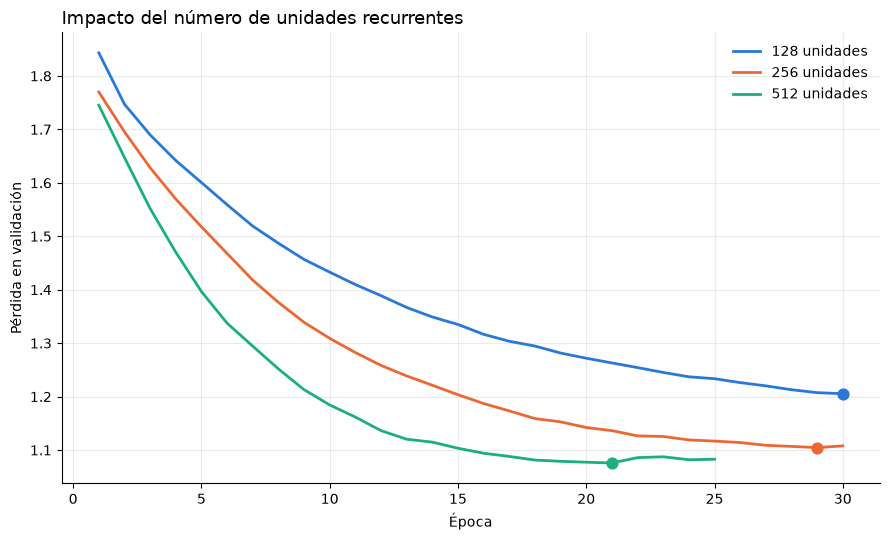

In [22]:
# Curvas de val_loss de las tres configuraciones
COLORES = {128: "#2a78d6", 256: "#eb6834", 512: "#1baf7a"}

fig, ax = plt.subplots(figsize=(9, 5.5))
for nombre, (m, h) in configs.items():
    curva = h['val_loss']
    ax.plot(range(1, len(curva)+1), curva, color=COLORES[int(nombre)],
            linewidth=2, label=f"{nombre} unidades")
    i = int(np.argmin(curva))
    ax.scatter([i+1], [curva[i]], color=COLORES[int(nombre)], s=60, zorder=3)

ax.set_xlabel("Época"); ax.set_ylabel("Pérdida en validación")
ax.set_title("Impacto del número de unidades recurrentes", loc='left', fontsize=13)
ax.legend(frameon=False); ax.grid(alpha=0.25)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

### Resultados de la comparación

| n_units | Parámetros | val_loss | val_accuracy | BLEU-1 | BLEU-4 | Épocas |
|---|---|---|---|---|---|---|
| 128 | 2.618.732 | 1.2054 | 0.8113 | 24.68 | 2.39 | 30 |
| 256 | 5.283.180 | 1.1046 | 0.8287 | 30.87 | 7.13 | 30 |
| 512 | 11.791.724 | **1.0758** | **0.8366** | **31.98** | **7.95** | 25 |

**Las métricas por token subestiman enormemente las diferencias.** Al pasar de 128 a 256
unidades, `val_loss` mejora un 8% y `val_accuracy` apenas un 2%, cifras que sugerirían
configuraciones casi equivalentes. BLEU-4, en cambio, se triplica: de 2.39 a 7.13.

La explicación está en cómo se componen los errores. Una traducción es una secuencia, y
BLEU-4 exige cuatro palabras consecutivas correctas. Si la probabilidad de acertar cada
token mejora ligeramente, la probabilidad de acertar cuatro seguidas mejora de forma
multiplicativa: una diferencia pequeña a nivel de token se amplifica a nivel de secuencia,
que es el nivel en el que se juzga una traducción.

Esto refuerza la conclusión de la sección anterior: evaluar un traductor con accuracy por
token es engañoso, y no sólo porque el valor absoluto sea optimista, sino porque **oculta
las diferencias entre modelos**. Las tres configuraciones tienen accuracy entre 0.81 y
0.84 —un rango estrecho— mientras su calidad real de traducción varía en un factor
superior a tres.

**Rendimientos decrecientes.** La mejora no escala con el tamaño:

| Salto | Parámetros | Tiempo por época | Mejora en BLEU-4 |
|---|---|---|---|
| 128 → 256 | ×2.0 | ×1.6 | ×3.0 |
| 256 → 512 | ×2.2 | ×1.9 | ×1.1 |

Duplicar de 128 a 256 triplica la calidad; volver a duplicar a 512 la mejora un 11%, con
4,5 veces los parámetros del modelo más chico y el triple de tiempo por época. El modelo
de 128 unidades resulta insuficiente para la tarea —un cuello de botella de 128
dimensiones no alcanza para representar frases completas—, mientras que entre 256 y 512 la
capacidad deja de ser el factor limitante.

La curva de pérdida de validación muestra el mismo patrón: el modelo de 512 unidades
desciende más rápido y se estabiliza alrededor de la época 21, el de 256 lo hace de forma
más gradual, y el de 128 llega al límite de 30 épocas todavía en descenso.

**Sobreajuste creciente.** La brecha entre la pérdida de entrenamiento y la de validación
crece con el tamaño: 0.34 en el modelo de 128, 0.53 en el de 256 y 0.61 en el de 512. El
de 512 fue además el único que activó tanto la reducción de la tasa de aprendizaje como el
early stopping, deteniéndose en la época 25. Con 16.987 pares de entrenamiento, un modelo
de casi 12 millones de parámetros empieza a memorizar antes de agotar lo que puede
aprender.

**Configuración recomendada: 256 unidades.** Obtiene el 90% del BLEU-4 del modelo de 512
con menos de la mitad de los parámetros y un tercio del tiempo de entrenamiento. El de 512
es mejor en términos absolutos, pero la diferencia no justifica el costo si el objetivo es
iterar.

*Nota metodológica:* el modelo de 128 unidades completó las 30 épocas todavía mejorando,
mientras que el de 512 convergió y se detuvo en la 25. La comparación favorece por lo
tanto ligeramente a las configuraciones grandes, aunque la diferencia de BLEU-4 entre 128
y 256 es demasiado amplia como para atribuirse a ese factor.

## 9. Conclusiones

**Sobre la extensión del modelo de clase.** Se duplicó el conjunto de entrenamiento
(20.000 pares frente a 10.000) y se ampliaron los límites de secuencia (22 y 24 tokens
frente a 20 y 22). El efecto fue consistente: la pérdida de validación bajó de 1.454 a
1.105 y el accuracy subió de 0.784 a 0.829 respecto del notebook de clase. Más datos
mejoran tanto el ajuste como la generalización, y la brecha entre entrenamiento y
validación se redujo.

**Sobre el tamaño de las capas recurrentes.** Es el resultado más informativo del trabajo.
Las métricas por token apenas distinguen las tres configuraciones —accuracy entre 0.81 y
0.84—, mientras que BLEU-4 varía de 2.39 a 7.95, un factor superior a tres. La razón es
que una traducción se evalúa a nivel de secuencia: pequeñas mejoras en la probabilidad de
acertar cada token se componen multiplicativamente al exigir varias palabras consecutivas
correctas. El salto de 128 a 256 unidades triplica la calidad; el de 256 a 512 la mejora
apenas un 11% al doble de costo. La capacidad deja de ser el factor limitante a partir de
las 256 unidades, y en cambio aparece el sobreajuste: la brecha entre pérdidas crece de
0.34 a 0.61 con el tamaño.

**Sobre la elección de métricas.** Evaluar un traductor con accuracy por token es engañoso
en dos sentidos. El valor absoluto es optimista, porque está dominado por las posiciones
de relleno, que son mayoría y triviales de predecir. Pero el problema mayor es que oculta
las diferencias entre modelos: configuraciones con calidades de traducción muy distintas
presentan accuracies casi idénticos. BLEU, al comparar n-gramas, refleja esas diferencias.

**Sobre la calidad de las traducciones.** Las frases cortas se traducen de forma
aceptable, con concordancia y orden correctos ("She bought a new car" → "ella compró un
coche nuevo"). Las frases largas se descarrilan después de las primeras palabras,
conservando el campo semántico pero perdiendo la estructura. El perfil de BLEU por orden
de n-grama lo cuantifica: 30.87 en unigramas contra 7.13 en 4-gramas, con cada orden
reteniendo aproximadamente el 60% del anterior. El modelo aprendió vocabulario, no
sintaxis extendida.

**Limitaciones del enfoque.** La principal es arquitectónica: toda la frase de entrada se
comprime en un par de vectores de tamaño fijo, independientemente de su longitud, y el
decoder no dispone de ninguna otra información. Ese cuello de botella es la limitación
conocida de los modelos encoder-decoder sin atención y explica el deterioro sistemático en
frases largas. Se suman tres factores: los embeddings del encoder son de 50 dimensiones y
están congelados, de modo que la representación de la entrada no se adapta a la tarea; el
vocabulario de español se recortó a 8.000 palabras, dejando fuera el 2,5% de los tokens; y
la generación es greedy, es decir, sin exploración de alternativas. También conviene notar
que BLEU se calcula contra una única referencia, cuando varias traducciones pueden ser
igualmente correctas, lo que deprime el valor reportado.

**Mejoras posibles.** En orden de impacto esperado: incorporar un mecanismo de atención,
que elimina el cuello de botella y es la diferencia arquitectónica decisiva para frases
largas; reemplazar la tokenización por palabra con una de subpalabras (BPE o SentencePiece),
que atacaría directamente la asimetría de vocabularios observada —11.533 formas distintas
en español contra 6.789 en inglés para el mismo contenido, producto de la flexión— y
eliminaría el recorte del vocabulario; usar embeddings de mayor dimensión y permitir su
ajuste durante el entrenamiento; y reemplazar la generación greedy por beam search.